## Short-Term Memory Sliding Window (Count/Token Pruning).
How Sliding Windows Work: In a standard chat graph, every turn appends messages to the messages list. A sliding window strategy ensures that only the last $N$ messages are kept in the active state context, preventing tokens from spiraling out of control during long chat sessions.

In [20]:
from langgraph.graph import END, StateGraph
from langgraph.graph.message import add_messages,RemoveMessage
from typing_extensions import Annotated, TypedDict
import operator

In [21]:
# 1. State definition using standard add_messages reducer
class State(TypedDict):
  messages: Annotated[list, add_messages]

In [25]:
# 2. Sliding Window Node (Trims messages keeping only the latest N)
def sliding_window_node(state: State):
  messages = state["messages"]

  # Define our max window size (e.g., keep only the last 4 messages)
  MAX_MESSAGES = 4

  if len(messages) > MAX_MESSAGES:
    # Identify messages to delete (everything except the last 4)
    messages_to_remove = [RemoveMessage(id=m.id) for m in messages[:-MAX_MESSAGES]]
    print(f"\n--- [Sliding Window Triggered] Pruning {len(messages_to_remove)} old messages ---")
    return {"messages": messages_to_remove}

  return {}



In [26]:

def model_node(state: State):
  print(f"\n--- [Model Node Running] Active message count: {len(state['messages'])} ---")
  last_msg = state["messages"][-1].content if hasattr(state["messages"][-1], 'content') else str(state["messages"][-1])
  return {"messages": [f"Echo response to: {last_msg}"]}

In [27]:
# 3. Build Graph
workflow = StateGraph(State)

workflow.add_node("window_trimmer", sliding_window_node)
workflow.add_node("model", model_node)

workflow.set_entry_point("window_trimmer")
workflow.add_edge("window_trimmer", "model")
workflow.add_edge("model", END)

app = workflow.compile()

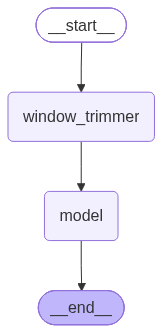

In [28]:
app

### testing

In [29]:
config = {"configurable": {"thread_id": "window_test_1"}}

# Let's simulate a conversation growing past 4 messages
chat_history = [
    "Msg 1: Hello",
    "Msg 2: Hi there",
    "Msg 3: What is FastAPI?",
    "Msg 4: It's a web framework",
    "Msg 5: Can you write a route?",
]

print("Invoking graph with 5 messages...")
result = app.invoke({"messages": chat_history}, config=config)

print("\nFinal State Message Array:")
for m in result["messages"]:
  print(f" - {m}")

Invoking graph with 5 messages...

--- [Sliding Window Triggered] Pruning 1 old messages ---

--- [Model Node Running] Active message count: 4 ---

Final State Message Array:
 - content='Msg 2: Hi there' additional_kwargs={} response_metadata={} id='5885e6f7-8d02-402f-95c3-030d28cc3547'
 - content='Msg 3: What is FastAPI?' additional_kwargs={} response_metadata={} id='00cd23d4-c0f6-4875-ac23-e56a0809d473'
 - content="Msg 4: It's a web framework" additional_kwargs={} response_metadata={} id='38d4e45c-9096-4359-b226-62a00d593336'
 - content='Msg 5: Can you write a route?' additional_kwargs={} response_metadata={} id='79e7ae5f-03eb-453a-b312-468eaad08d92'
 - content='Echo response to: Msg 5: Can you write a route?' additional_kwargs={} response_metadata={} id='06cc985a-173a-4892-9c3c-7eec5495ee12'


2. Token-based trimming: Keeps messages based on a maximum token budget rather than a fixed message count.
For example, if MAX_TOKENS = 1000, we retain as much recent conversation as possible without exceeding that budget.
Key difference:
- Count-based → Limits the number of messages.
- Token-based → Limits the number of tokens.